# 02. Feature Engineering & Exploratory Data Analysis (EDA)

## Objective
Raw relational columns alone cannot be directly consumed by machine learning algorithms effectively. In this phase, we transform timestamps, zip codes, and dimensional attributes into actionable domain-specific features:

1. **Spatial Features:** Calculate Haversine distance between customer and seller geo-coordinates and flag cross-state transfers.
2. **Temporal Features:** Extract day-of-week, hour-of-day, and estimated promised shipping duration.
3. **Volumetric Traits:** Compute package volume from physical length, height, and width.
4. **Data Hygiene:** Impute missing physical values and save the cleaned dataset to `data/processed/`.

In [2]:
import pandas as pd
import numpy as np

# Load intermediate dataset produced by Notebook 01
df_master = pd.read_csv('../data/interim/df_master_merged.csv')

# Re-parse datetime columns (CSV format converts timestamps back to text)
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    df_master[col] = pd.to_datetime(df_master[col])

print(f"Loaded master dataframe successfully. Shape: {df_master.shape}")

Loaded master dataframe successfully. Shape: (96470, 23)


In [3]:
# Load geolocation coordinates dataset
geo = pd.read_csv('../data/raw/olist_geolocation_dataset.csv')

# Geolocation contains multiple coordinate entries per zip code prefix; aggregate to mean lat/lng
geo_clean = geo.groupby('geolocation_zip_code_prefix').agg(
    lat=('geolocation_lat', 'mean'),
    lng=('geolocation_lng', 'mean')
).reset_index()

# Merge customer lat/lng into df_master
df_master = pd.merge(
    df_master, 
    geo_clean.rename(columns={
        'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
        'lat': 'customer_lat',
        'lng': 'customer_lng'
    }), 
    on='customer_zip_code_prefix', 
    how='left'
)

# Merge seller lat/lng into df_master
df_master = pd.merge(
    df_master, 
    geo_clean.rename(columns={
        'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
        'lat': 'seller_lat',
        'lng': 'seller_lng'
    }), 
    on='seller_zip_code_prefix', 
    how='left'
)

print(f"Coordinates mapped. Missing customer coords: {df_master['customer_lat'].isna().sum()}, Missing seller coords: {df_master['seller_lat'].isna().sum()}")

Coordinates mapped. Missing customer coords: 264, Missing seller coords: 215


### 1. Spatial Distance Calculation (Haversine Formula)

Zip codes are arbitrary string labels, which tree models cannot natively interpret as geographical positions. We convert latitude and longitude pairs into continuous physical distance using the **Haversine formula**:

$$d = 2r \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta \phi}{2}\right) + \cos(\phi_1)\cos(\phi_2)\sin^2\left(\frac{\Delta \lambda}{2}\right)}\right)$$

Where $\phi$ represents latitude, $\lambda$ represents longitude in radians, and $r = 6371\text{ km}$ (Earth's radius).

We also create `is_same_state` to capture logistical friction caused by interstate shipping regulations and multi-state transport networks.

In [4]:
def haversine_distance(lat1, lon1, lat2, lon2):
    """Calculates Haversine distance between two points in kilometers."""
    r = 6371.0  # Earth's radius in km
    
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    
    return r * c

# Apply spatial distance formula
df_master['distance_km'] = haversine_distance(
    df_master['customer_lat'], df_master['customer_lng'],
    df_master['seller_lat'], df_master['seller_lng']
)

# Flag intra-state vs interstate delivery
df_master['is_same_state'] = (df_master['customer_state'] == df_master['seller_state']).astype(int)

# Inspect spatial summary statistics
df_master[['distance_km', 'is_same_state']].describe()

,distance_km,is_same_state
count,95992.000000,96470.000000
mean,600.757241,0.359708
std,593.711747,0.479917
min,0.000000,0.000000
25%,185.933322,0.000000
50%,433.872060,0.000000
75%,798.548675,1.000000
max,8677.911622,1.000000


### 2. Temporal & Volumetric Feature Extraction

We derive signals that capture logistics complexity:
1. **`estimated_days`:** Difference between promised delivery date and purchase timestamp ($\text{estimated\_days} = \text{delivery\_date} - \text{purchase\_time}$). Tighter promises lead to higher delay risk.
2. **`purchase_dow` & `purchase_hour`:** Day-of-week (0=Mon, 6=Sun) and hour of order placement. Orders placed late Friday or over the weekend suffer processing lag.
3. **`product_volume_cm3`:** Physical dimensions ($\text{length} \times \text{height} \times \text{width}$). Oversized cargo requires specialized freight logistics.

In [5]:
# 1. Temporal promised window (in days)
df_master['estimated_days'] = (
    df_master['order_estimated_delivery_date'] - df_master['order_purchase_timestamp']
).dt.total_seconds() / (24 * 3600)

# 2. Purchase timing signals
df_master['purchase_dow'] = df_master['order_purchase_timestamp'].dt.dayofweek
df_master['purchase_hour'] = df_master['order_purchase_timestamp'].dt.hour

# 3. Package physical volume
df_master['product_volume_cm3'] = (
    df_master['product_length_cm'] * 
    df_master['product_height_cm'] * 
    df_master['product_width_cm']
)

# Inspect engineered feature samples
df_master[['estimated_days', 'purchase_dow', 'purchase_hour', 'product_volume_cm3']].head()

,estimated_days,purchase_dow,purchase_hour,product_volume_cm3
0,15.544063,0,10,1976.0
1,19.137766,1,20,4693.0
2,26.639711,2,8,9576.0
3,26.188819,5,19,6000.0
4,12.112049,1,21,11475.0


### 3. Exploratory Data Analysis (EDA)

We plot the engineered features against our target variable (`is_delayed`) to confirm feature signals before feeding them into machine learning models.

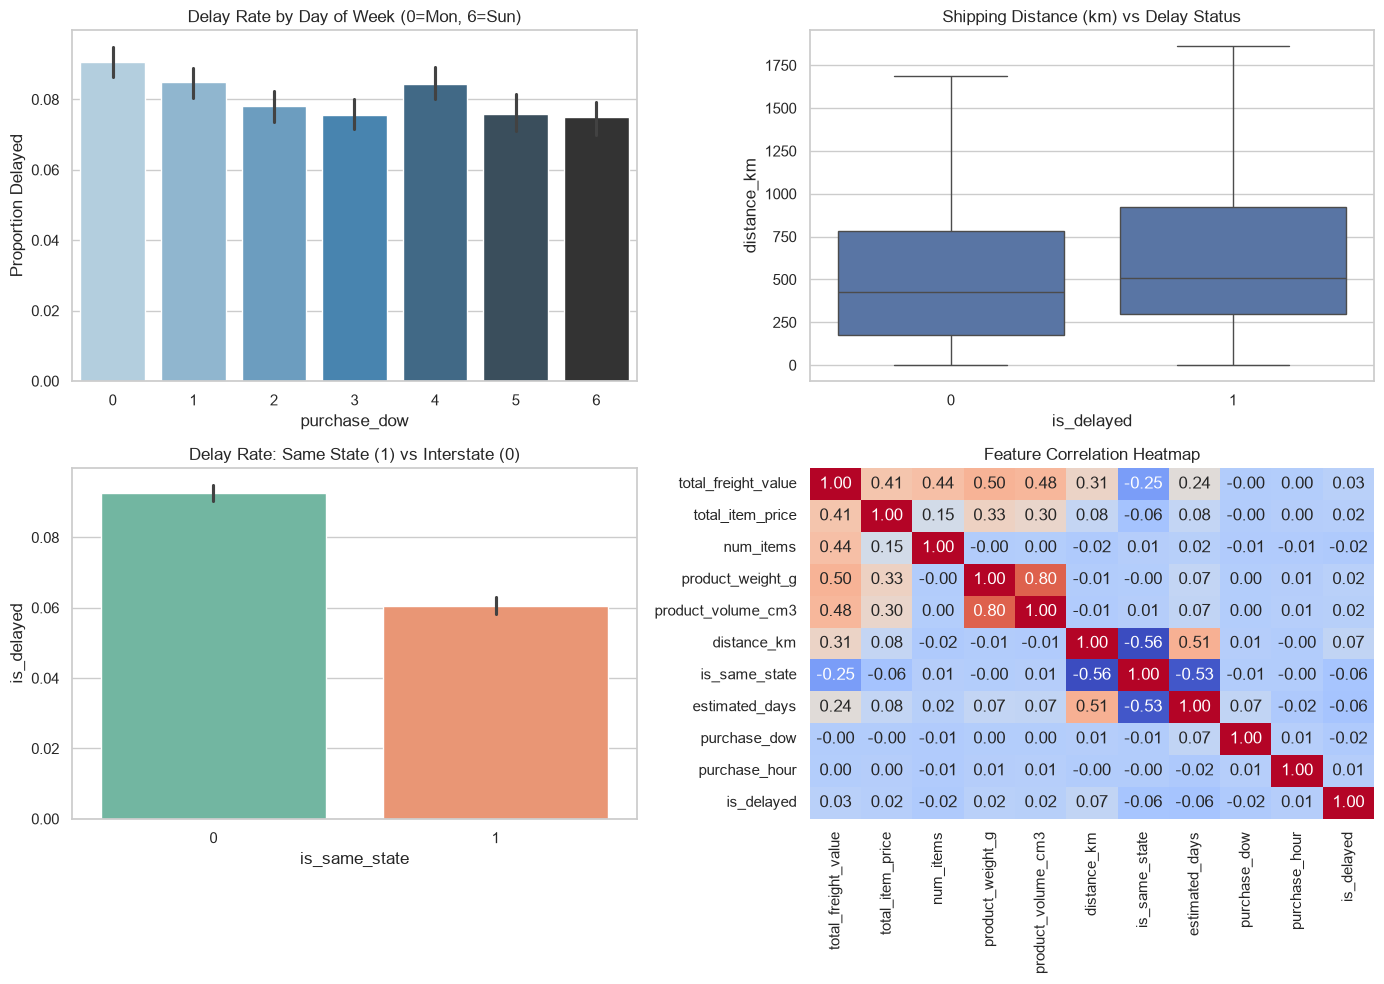

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Delay rate by Purchase Day of Week
sns.barplot(
    data=df_master, 
    x='purchase_dow', 
    y='is_delayed', 
    hue='purchase_dow', 
    ax=axes[0, 0], 
    palette='Blues_d', 
    legend=False
)
axes[0, 0].set_title('Delay Rate by Day of Week (0=Mon, 6=Sun)')
axes[0, 0].set_ylabel('Proportion Delayed')

# 2. Shipping Distance vs Delay
sns.boxplot(
    data=df_master, 
    x='is_delayed', 
    y='distance_km', 
    ax=axes[0, 1], 
    showfliers=False
)
axes[0, 1].set_title('Shipping Distance (km) vs Delay Status')

# 3. Same State vs Interstate Delay Rate
sns.barplot(
    data=df_master, 
    x='is_same_state', 
    y='is_delayed', 
    hue='is_same_state', 
    ax=axes[1, 0], 
    palette='Set2', 
    legend=False
)
axes[1, 0].set_title('Delay Rate: Same State (1) vs Interstate (0)')

# 4. Correlation Heatmap
numerical_cols = [
    'total_freight_value', 'total_item_price', 'num_items', 
    'product_weight_g', 'product_volume_cm3', 'distance_km', 
    'is_same_state', 'estimated_days', 'purchase_dow', 'purchase_hour', 'is_delayed'
]
corr = df_master[numerical_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

### 4. Data Imputation & Processed Dataset Export

#### Why Median Imputation?
Physical traits (`distance_km`, `product_weight_g`, `product_volume_cm3`) contain right-skewed distributions caused by rare oversized shipments. Filling missing values with the **median** prevents extreme outliers from distorting the feature distributions.

We drop raw string IDs and non-predictive timestamps, preserving only numerical feature columns for model training.

In [9]:
import os

feature_cols = [
    'total_freight_value',
    'total_item_price',
    'num_items',
    'product_weight_g',
    'product_volume_cm3',
    'distance_km',
    'is_same_state',
    'estimated_days',
    'purchase_dow',
    'purchase_hour'
]

target_col = 'is_delayed'

# Median imputation for missing physical properties
for col in ['product_weight_g', 'product_volume_cm3', 'distance_km']:
    df_master[col] = df_master[col].fillna(df_master[col].median())

# Extract final numerical feature matrix
df_final = df_master[feature_cols + [target_col]].copy()

# Confirm zero missing values
print("Missing values in final processed dataset:")
print(df_final.isna().sum())

# Export processed dataset to data/processed/
os.makedirs('../data/processed', exist_ok=True)
df_final.to_csv('../data/processed/olist_processed.csv', index=False)
print(f"\nNotebook 02 complete! Saved processed dataset to data/processed/olist_processed.csv. Shape: {df_final.shape}")

Missing values in final processed dataset:
total_freight_value    0
total_item_price       0
num_items              0
product_weight_g       0
product_volume_cm3     0
distance_km            0
is_same_state          0
estimated_days         0
purchase_dow           0
purchase_hour          0
is_delayed             0
dtype: int64

Notebook 02 complete! Saved processed dataset to data/processed/olist_processed.csv. Shape: (96470, 11)


## Summary: Feature Engineering & Selection Rationale

### 1. Engineered Features (Signal Compression)
* **`distance_km`:** Derived from customer and seller latitude/longitude coordinates via the Haversine formula. Replaces arbitrary string zip codes with continuous spatial distance.
* **`is_same_state`:** Compresses categorical state attributes (`customer_state`, `seller_state`) into a binary flag indicating interstate logistics friction.
* **`product_volume_cm3`:** Combines individual physical dimensions (`length`, `width`, `height`) into a single volumetric footprint.
* **`estimated_days`**, **`purchase_dow`**, **`purchase_hour`:** Extracted from raw timestamps to measure promised delivery window tightness and checkout operational timing.

### 2. Omitted Primary Keys (Overfitting Prevention)
* **`order_id`**, **`customer_id`**, **`seller_id`**, **`product_id`:** Unique string identifiers carry no generalizable predictive signal and cause decision trees to overfit on specific entity hashes.

### 3. Omitted Timestamps (Data Leakage Prevention)
* **`order_delivered_customer_date`**, **`order_delivered_carrier_date`**, **`order_approved_at`:** These timestamps occur *after* checkout and are unavailable at inference time when making real-time delay predictions.

### 4. Omitted High-Cardinality Strings
* **`customer_city`**, **`seller_city`:** Excluded to avoid adding 5,000+ sparse dummy columns, which causes the Curse of Dimensionality.